In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import random
from scipy.sparse import csr_matrix
from scipy.stats import skew, kurtosis

import matplotlib
import matplotlib.pyplot as plt

# DropSeq MCF7_Filtered_Normalised_3000_Data_train EDA

We perform some basic exploratory data analysis on our training dataset to better understand it and its characteristics.

In [2]:
dfn = pd.read_csv("/Users/elizabeth/Desktop/DropSeq/MCF7_Filtered_Normalised_3000_Data_train.txt",delimiter="\ ",engine='python',index_col=0)

In [3]:
dfn.shape

(3000, 21626)

In [4]:
dfn.head()

,"""AAAAACCTATCG_Normoxia""","""AAAACAACCCTA_Normoxia""","""AAAACACTCTCA_Normoxia""","""AAAACCAGGCAC_Normoxia""","""AAAACCTAGCTC_Normoxia""","""AAAACCTCCGGG_Normoxia""","""AAAACTCGTTGC_Normoxia""","""AAAAGAGCTCTC_Normoxia""","""AAAAGCTAGGCG_Normoxia""","""AAAATCGCATTT_Normoxia""",...,"""TTTTACAGGATC_Hypoxia""","""TTTTACCACGTA_Hypoxia""","""TTTTATGCTACG_Hypoxia""","""TTTTCCAGACGC_Hypoxia""","""TTTTCGCGCTCG_Hypoxia""","""TTTTCGCGTAGA_Hypoxia""","""TTTTCGTCCGCT_Hypoxia""","""TTTTCTCCGGCT_Hypoxia""","""TTTTGTTCAAAG_Hypoxia""","""TTTTTTGTATGT_Hypoxia"""
"""MALAT1""",1,3,3,6,4,5,1,13,3,3,...,0,2,1,0,1,0,1,0,0,4
"""MT-RNR2""",0,0,0,2,0,0,2,1,7,0,...,0,0,0,0,0,0,0,0,0,0
"""NEAT1""",0,0,0,0,0,2,0,1,2,0,...,0,0,0,0,0,0,0,0,0,0
"""H1-5""",0,0,0,0,0,2,0,0,0,0,...,0,1,0,0,1,0,0,1,0,0
"""TFF1""",4,1,1,1,0,0,0,2,0,1,...,2,3,8,0,0,3,4,2,6,0


In [5]:
dfn.describe()

,"""AAAAACCTATCG_Normoxia""","""AAAACAACCCTA_Normoxia""","""AAAACACTCTCA_Normoxia""","""AAAACCAGGCAC_Normoxia""","""AAAACCTAGCTC_Normoxia""","""AAAACCTCCGGG_Normoxia""","""AAAACTCGTTGC_Normoxia""","""AAAAGAGCTCTC_Normoxia""","""AAAAGCTAGGCG_Normoxia""","""AAAATCGCATTT_Normoxia""",...,"""TTTTACAGGATC_Hypoxia""","""TTTTACCACGTA_Hypoxia""","""TTTTATGCTACG_Hypoxia""","""TTTTCCAGACGC_Hypoxia""","""TTTTCGCGCTCG_Hypoxia""","""TTTTCGCGTAGA_Hypoxia""","""TTTTCGTCCGCT_Hypoxia""","""TTTTCTCCGGCT_Hypoxia""","""TTTTGTTCAAAG_Hypoxia""","""TTTTTTGTATGT_Hypoxia"""
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,...,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,0.034000,0.030333,0.027000,0.032333,0.045333,0.047333,0.030000,0.027333,0.032000,0.027333,...,0.052333,0.043667,0.033667,0.033000,0.025333,0.037000,0.046333,0.055667,0.038000,0.033000
std,0.277254,0.220823,0.195662,0.233751,0.246235,0.299649,0.204403,0.292030,0.281074,0.237918,...,0.364654,0.244499,0.340449,0.302117,0.208261,0.286924,0.301469,0.358623,0.240642,0.244808
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,4.000000,4.000000,5.000000,6.000000,4.000000,8.000000,6.000000,13.000000,7.000000,6.000000,...,7.000000,4.000000,10.000000,8.000000,6.000000,7.000000,7.000000,9.000000,6.000000,6.000000


In [6]:
dfn.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3000 entries, "MALAT1" to "SUDS3"
Columns: 21626 entries, "AAAAACCTATCG_Normoxia" to "TTTTTTGTATGT_Hypoxia"
dtypes: int64(21626)
memory usage: 495.0+ MB


We transpose our dataframe so that the rows represent cells and the columns genes, which will facilitate some parts of our analysis later on.

In [7]:
dfn_t = dfn.T

In [8]:
dfn_t.shape

(21626, 3000)

In [9]:
dfn_t.head()

,"""MALAT1""","""MT-RNR2""","""NEAT1""","""H1-5""","""TFF1""","""MT-RNR1""","""H4C3""","""GDF15""","""KRT81""","""MT-CO3""",...,"""MROH1""","""SKIDA1""","""MICALL1""","""RARG""","""MYO1F""","""BRWD1-AS2""","""RPS19BP1""","""AUNIP""","""TNK2""","""SUDS3"""
"""AAAAACCTATCG_Normoxia""",1,0,0,0,4,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"""AAAACAACCCTA_Normoxia""",3,0,0,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"""AAAACACTCTCA_Normoxia""",3,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"""AAAACCAGGCAC_Normoxia""",6,2,0,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"""AAAACCTAGCTC_Normoxia""",4,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [10]:
dfn_t.describe()

,"""MALAT1""","""MT-RNR2""","""NEAT1""","""H1-5""","""TFF1""","""MT-RNR1""","""H4C3""","""GDF15""","""KRT81""","""MT-CO3""",...,"""MROH1""","""SKIDA1""","""MICALL1""","""RARG""","""MYO1F""","""BRWD1-AS2""","""RPS19BP1""","""AUNIP""","""TNK2""","""SUDS3"""
count,21626.000000,21626.000000,21626.000000,21626.000000,21626.000000,21626.000000,21626.000000,21626.000000,21626.000000,21626.000000,...,21626.000000,21626.000000,21626.000000,21626.000000,21626.000000,21626.000000,21626.000000,21626.000000,21626.000000,21626.000000
mean,3.634791,0.850458,0.136086,0.368862,1.799362,0.291362,1.730972,0.011884,0.026912,0.105105,...,0.008046,0.002035,0.003930,0.016138,0.000971,0.000832,0.034172,0.002405,0.003884,0.088042
std,6.837353,1.721088,0.643060,0.953887,2.486034,0.740664,2.328460,0.189425,0.233430,0.387558,...,0.092892,0.048995,0.065461,0.131046,0.032598,0.028839,0.200548,0.053491,0.064395,0.323733
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,4.000000,1.000000,0.000000,0.000000,3.000000,0.000000,2.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,175.000000,32.000000,23.000000,22.000000,46.000000,16.000000,44.000000,20.000000,17.000000,5.000000,...,2.000000,3.000000,2.000000,3.000000,2.000000,1.000000,4.000000,3.000000,2.000000,3.000000


Even though the data set is filtered and normalized we check for any missing values and duplicates since occurance of errors is always a possibility.

In [11]:
dfn_t.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21626 entries, "AAAAACCTATCG_Normoxia" to "TTTTTTGTATGT_Hypoxia"
Columns: 3000 entries, "MALAT1" to "SUDS3"
dtypes: int64(3000)
memory usage: 495.6+ MB


We verify that all values are integers

In [12]:
dfn.isnull().sum().sum()

0

There are no missing values

In [13]:
duplicate_rows_tot = dfn_t.duplicated(keep=False).sum()
print(f"There are {duplicate_rows_tot} duplicate rows.")

There are 0 duplicate rows.


In [14]:
duplicate_cols = dfn_t.T.duplicated(keep=False).sum()
print(f"There are {duplicate_cols} duplicate columns.")

There are 0 duplicate columns.


**Sparcity**

<AxesSubplot:>

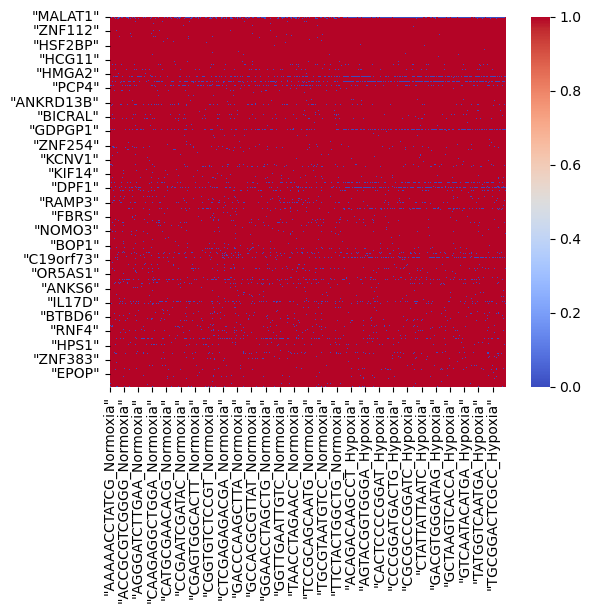

In [15]:
sns.heatmap(dfn == 0, cmap="coolwarm")

In [16]:
sparse_dfn = csr_matrix(dfn.values) # Converts DataFrame into a CSR sparse matrix
print(sparse_dfn)

density_n = np.count_nonzero(sparse_dfn.toarray()) / np.prod(sparse_dfn.shape)
print(f"Sparsity: {1 - density_n:.2%}")

  (0, 0)	1
  (0, 1)	3
  (0, 2)	3
  (0, 3)	6
  (0, 4)	4
  (0, 5)	5
  (0, 6)	1
  (0, 7)	13
  (0, 8)	3
  (0, 9)	3
  (0, 10)	7
  (0, 11)	5
  (0, 12)	3
  (0, 13)	4
  (0, 14)	2
  (0, 15)	1
  (0, 16)	2
  (0, 17)	2
  (0, 18)	10
  (0, 19)	10
  (0, 20)	10
  (0, 21)	6
  (0, 22)	1
  (0, 23)	5
  (0, 24)	4
  :	:
  (2999, 21383)	1
  (2999, 21385)	1
  (2999, 21387)	1
  (2999, 21413)	1
  (2999, 21417)	1
  (2999, 21421)	1
  (2999, 21438)	1
  (2999, 21464)	1
  (2999, 21474)	1
  (2999, 21477)	1
  (2999, 21479)	2
  (2999, 21481)	1
  (2999, 21500)	1
  (2999, 21504)	1
  (2999, 21507)	1
  (2999, 21509)	1
  (2999, 21510)	1
  (2999, 21518)	1
  (2999, 21532)	1
  (2999, 21543)	1
  (2999, 21553)	1
  (2999, 21579)	1
  (2999, 21593)	2
  (2999, 21600)	1
  (2999, 21623)	1
Sparsity: 97.53%


The level of sparsity is 97.53% indicating that the data obtained using DropSeq is much more sparse than the SmartSeq

Sparse DropSeq data can be expected because of the sequencing technique, which involves encapsulating individual cells in nanoliter-sized droplets and then sequencing the RNA from each droplet separately. Since each droplet contains only a single cell, the resulting sequencing data is inherently sparse and so the sequencing reads for each gene are only observed in a subset of the cells.

**Skewness and Kurtosis**

Skweness is the measure of the lack of symmetry in the data set and kurtosis is the measure of peakness of distribution

Text(0.5, 1.0, 'Distribution of skewness values for genes')

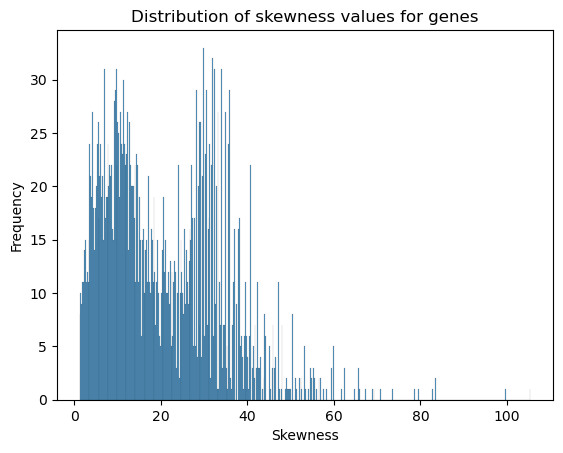

In [17]:
column_num = np.shape(dfn)[1]
cells_n = list(dfn.columns)

skewness = dfn.apply(skew, axis=1)
sns.histplot(skewness, bins=500)  # skewness of genes
plt.xlabel('Skewness')
plt.ylabel('Frequency')
plt.title('Distribution of skewness values for genes')

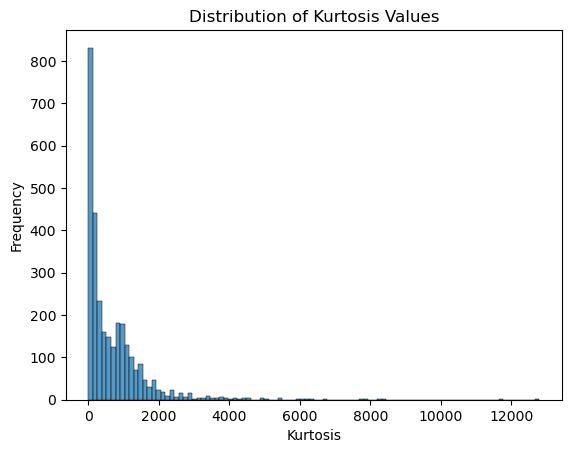

In [18]:
kurt = kurtosis(dfn, axis=1)

sns.histplot(kurt, bins=100)
plt.xlabel('Kurtosis')
plt.ylabel('Frequency')
plt.title('Distribution of Kurtosis Values')
plt.show()

**Distribution**

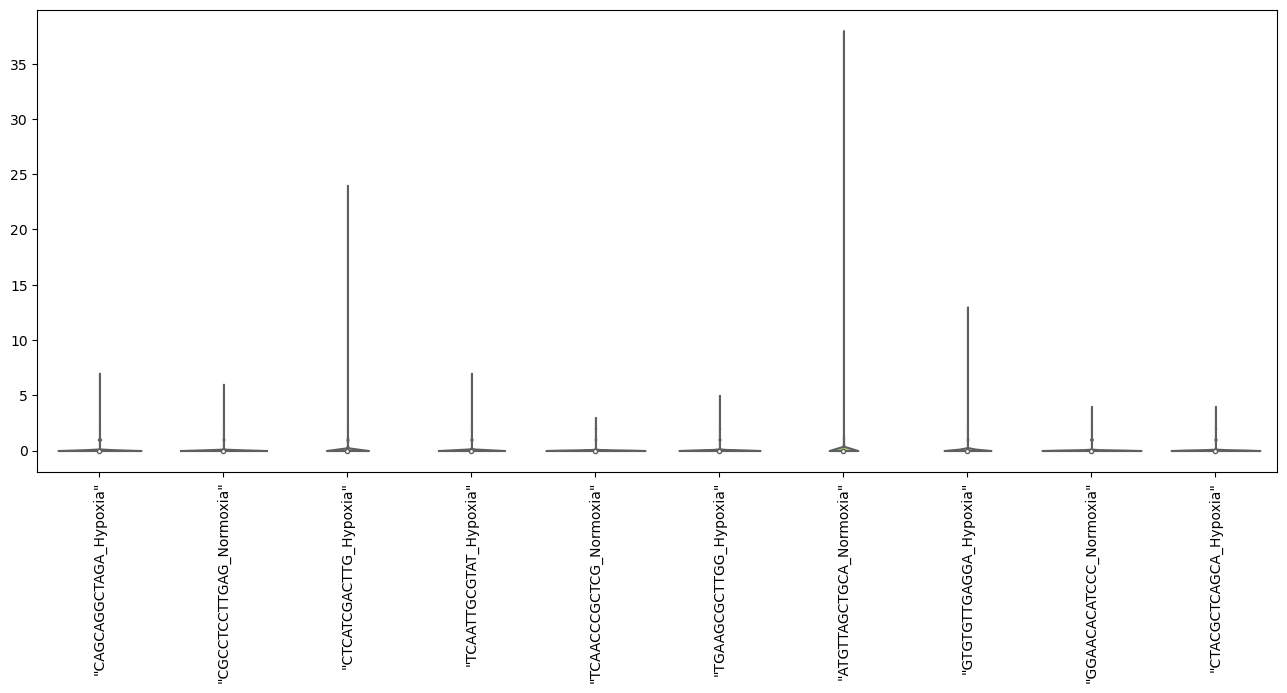

In [19]:
n = 10
random_cells_n = np.random.choice(dfn.columns, size=n, replace=False)
plt.figure(figsize=(16,6))
violin_plot = sns.violinplot(data=dfn[random_cells_n], palette="Set3", cut=0)
plt.setp(violin_plot.get_xticklabels(), rotation=90)
plt.show()

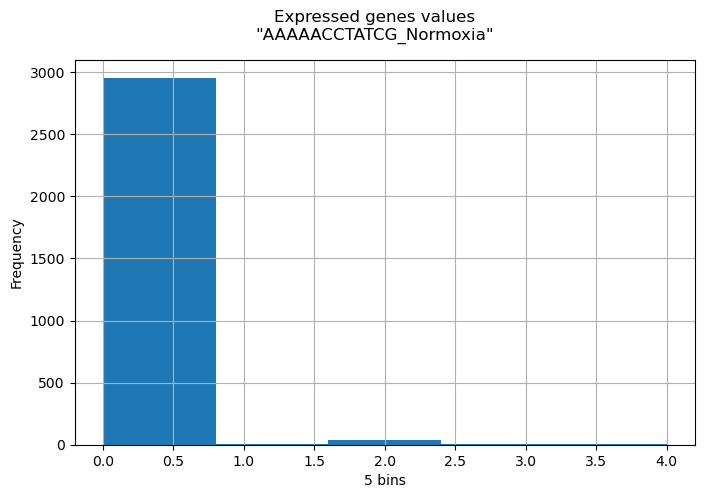

In [20]:
#histogram of a single column
col = dfn.iloc[:, 0]
fig, axs = plt.subplots(1, 1, figsize=(8, 5))
col.hist(bins=5)
plt.suptitle(f"Expressed genes values\n{col.name}")
axs.set_xlabel("5 bins")
axs.set_ylabel("Frequency")
plt.show()


So we see that the distributions are highly non-normal, very skewed with heavy tails.

**Correlation**

Now we want to check correlation between samples using the Pearson correlation coefficient

In [21]:
#pearson correlation coefficient
random.seed(42)
random_columns = [i for i in range(0,dfn.shape[0])]
random.shuffle(random_columns)

corr_matrix_p = dfn.iloc[:, random_columns[:1000]].corr(method = 'pearson') #correlation matrix made of 250 random columns

average = (corr_matrix_p.values.max() - corr_matrix_p.values.min()) /2 + corr_matrix_p.values.min()
print("Number of cells included: ", np.shape(corr_matrix_p))
print("Average between minimum and maximum correlation: ", average)
print("Average correlation of expression profiles between genes: ", corr_matrix_p.mean().mean())

Number of cells included:  (1000, 1000)
Average between minimum and maximum correlation:  0.49272467710631324
Average correlation of expression profiles between genes:  0.26583308782243453


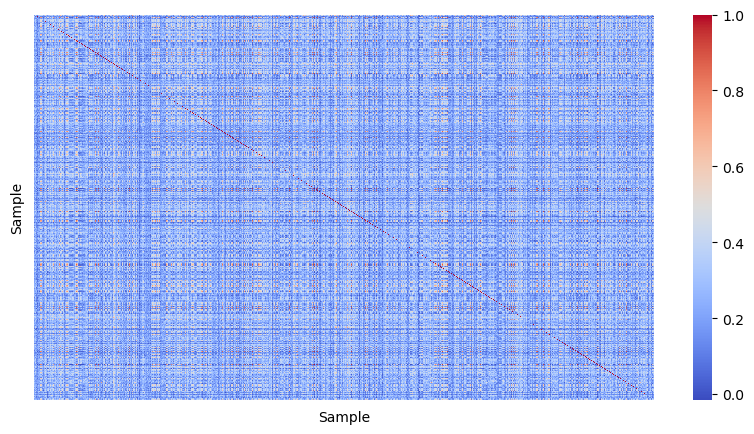

In [22]:
plt.figure(figsize=(10,5))
sns.heatmap(corr_matrix_p, cmap='coolwarm', yticklabels = False, xticklabels = False)
plt.xlabel('Sample')
plt.ylabel('Sample')
plt.show()

**Filtering**

Filtering based on total read counts involves setting a threshold on the total number of reads (or counts) for each cell. Cells with counts below the threshold are typically considered to have low sequencing depth and may be filtered out from further analysis. This type of filtering aims to remove cells with low library sizes or poor quality data.

Filtering based on the number of non-zero genes, on the other hand, involves setting a threshold on the number of genes that have non-zero counts for each cell. Cells with a low number of expressed genes below the threshold may be considered low-quality or uninformative and can be excluded from downstream analysis.

While both filtering approaches can help remove low-quality or uninformative cells, they capture different aspects of the data. Filtering based on total read counts focuses on the overall sequencing depth of each cell, while filtering based on the number of non-zero genes examines the transcriptional activity and the diversity of expressed genes within each cell.

In [3]:
total_counts = np.sum(dfn, axis=0)

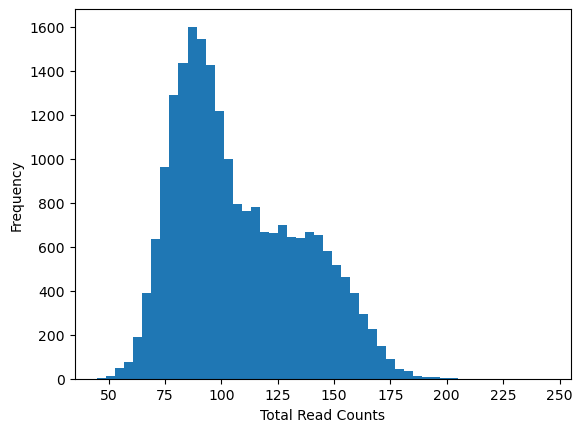

In [4]:
plt.hist(total_counts, bins=50)

plt.xlabel('Total Read Counts')
plt.ylabel('Frequency')

plt.show()

We can set the threshold at 65

In [5]:
dfn_filtered = dfn.loc[:, total_counts >= 65]

Now for the non-zero genes

In [6]:
nonzero_counts = np.count_nonzero(dfn_filtered, axis=0)

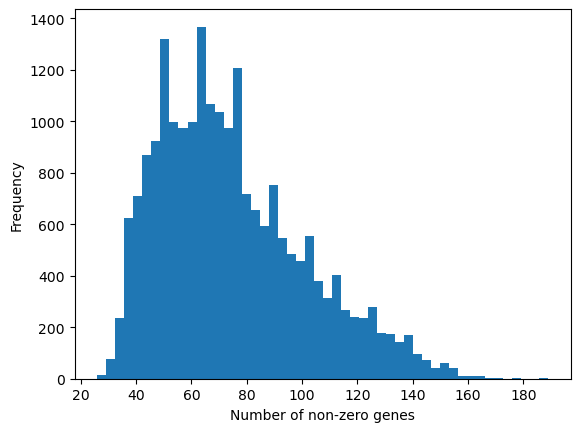

In [7]:
plt.hist(nonzero_counts, bins=50)
plt.xlabel('Number of non-zero genes')
plt.ylabel('Frequency')
plt.show()

We set the threshold at 35

In [8]:
dfn_filtered = dfn_filtered.loc[:, nonzero_counts >= 35]

In [9]:
dfn_filtered

,"""AAAAACCTATCG_Normoxia""","""AAAACAACCCTA_Normoxia""","""AAAACACTCTCA_Normoxia""","""AAAACCAGGCAC_Normoxia""","""AAAACCTAGCTC_Normoxia""","""AAAACCTCCGGG_Normoxia""","""AAAACTCGTTGC_Normoxia""","""AAAAGAGCTCTC_Normoxia""","""AAAAGCTAGGCG_Normoxia""","""AAAATCGCATTT_Normoxia""",...,"""TTTTACAGGATC_Hypoxia""","""TTTTACCACGTA_Hypoxia""","""TTTTATGCTACG_Hypoxia""","""TTTTCCAGACGC_Hypoxia""","""TTTTCGCGCTCG_Hypoxia""","""TTTTCGCGTAGA_Hypoxia""","""TTTTCGTCCGCT_Hypoxia""","""TTTTCTCCGGCT_Hypoxia""","""TTTTGTTCAAAG_Hypoxia""","""TTTTTTGTATGT_Hypoxia"""
"""MALAT1""",1,3,3,6,4,5,1,13,3,3,...,0,2,1,0,1,0,1,0,0,4
"""MT-RNR2""",0,0,0,2,0,0,2,1,7,0,...,0,0,0,0,0,0,0,0,0,0
"""NEAT1""",0,0,0,0,0,2,0,1,2,0,...,0,0,0,0,0,0,0,0,0,0
"""H1-5""",0,0,0,0,0,2,0,0,0,0,...,0,1,0,0,1,0,0,1,0,0
"""TFF1""",4,1,1,1,0,0,0,2,0,1,...,2,3,8,0,0,3,4,2,6,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"""BRWD1-AS2""",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"""RPS19BP1""",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"""AUNIP""",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"""TNK2""",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
